<a href="https://colab.research.google.com/github/Fahikader/Customer-Request-Classification/blob/main/Bitext_dataset_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Support Intent Classification Using Machine Learning

## Dataset Analysis and Model Comparison

This notebook analyses the Bitext Customer Support dataset and prepares it for a text-classification experiment. The experiment uses the customer message in the `instruction` column to predict the corresponding customer-support intent in the `intent` column.

Four traditional machine-learning algorithms are compared: Multinomial Naive Bayes, Logistic Regression, Linear Support Vector Machine (SVM), and Random Forest. The text is converted into numerical features using TF-IDF.

The notebook covers dataset inspection, data splitting, model training, evaluation, and error analysis.


## 1. Import the Required Libraries

The libraries in this section are used for the following tasks:

- loading and handling the dataset;
- inspecting and analysing the data;
- separating the data into training and testing sets;
- converting text into TF-IDF features;
- training the classification models; and
- evaluating and visualising model predictions.


In [1]:
# Data handling
import pandas as pd

# Dataset loading
from datasets import load_dataset

# Splitting the dataset into training and testing groups
from sklearn.model_selection import GroupShuffleSplit

# Text representation and machine-learning pipelines
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

# Classification algorithms
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics and error-analysis tools
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 2. Load the Dataset

The Bitext Customer Support dataset is loaded from Hugging Face. The `train` split is converted into a pandas DataFrame so that its records and columns can be examined using Python.

The resulting DataFrame is stored in the variable `df`.


In [2]:
print("Loading the Bitext customer support dataset...")

hf_dataset = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset",
    split="train"
)

df = hf_dataset.to_pandas()

print("Dataset loaded successfully.")

Loading the Bitext customer support dataset...


README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

Bitext_Sample_Customer_Support_Training_(…): reconstructing file:   0%|          |  0.00B / 19.2MB            

Bitext_Sample_Customer_Support_Training_(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]

Dataset loaded successfully.


## 3. Initial Dataset Inspection

This section examines the basic structure and quality of the dataset before model training.

### 3.1 Dataset structure

The dataset shape shows the number of records and columns. The column names and data types are also displayed, together with the first five records.

These checks help confirm that the dataset has been loaded and that the expected fields are available.


In [3]:
print("DATASET STRUCTURE")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
display(df.head())

DATASET STRUCTURE
Number of rows: 26872
Number of columns: 5

Column names:
['flags', 'instruction', 'category', 'intent', 'response']

Data types:
flags          object
instruction    object
category       object
intent         object
response       object
dtype: object

First five records:


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


### 3.2 Check for missing values

This check counts missing values in each column and calculates the total number of missing values in the dataset.

If any rows contain missing values, they are displayed so that they can be examined.


In [4]:
print("MISSING VALUES")

missing_values = df.isnull().sum()
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

print("\nRows containing at least one missing value:")
display(df[df.isnull().any(axis=1)])

MISSING VALUES
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

Total missing values: 0

Rows containing at least one missing value:


,flags,instruction,category,intent,response


### 3.3 Check for fully duplicated records

This check counts rows that are identical across all columns.

A fully duplicated record is different from a repeated customer instruction. Two records may contain the same instruction but have different values in another column, so they are not necessarily fully duplicated rows.


In [5]:
print("FULLY DUPLICATED RECORDS")

duplicated_rows = df.duplicated().sum()
print("Number of fully duplicated rows:", duplicated_rows)

FULLY DUPLICATED RECORDS
Number of fully duplicated rows: 0


### 3.4 Check for repeated customer instructions

This section examines repeated values in the `instruction` column.

It reports:
- the number of instruction entries that repeat after their first occurrence; and
- the number of distinct instruction texts that appear more than once.

Repeated instructions are relevant when preparing the train-test split because identical text should not appear in both sets.


In [6]:
print("REPEATED CUSTOMER INSTRUCTIONS")

duplicated_requests = df["instruction"].duplicated().sum()
print("Repeated instruction entries:", duplicated_requests)

instruction_counts = df["instruction"].value_counts()
unique_repeated_texts = (instruction_counts > 1).sum()

print(
    "Unique instruction texts appearing more than once:",
    unique_repeated_texts
)

REPEATED CUSTOMER INSTRUCTIONS
Repeated instruction entries: 2237
Unique instruction texts appearing more than once: 989


### 3.5 Examine the intent distribution

The `intent` column contains the specific customer-support intent that the classification models will predict.

This section counts the records for each intent and calculates the percentage represented by each intent. It also reports the number of unique intent classes.


In [7]:
print("INTENT DISTRIBUTION")

intent_counts = df["intent"].value_counts(dropna=False)
print(intent_counts)

print("\nNumber of unique intents:", df["intent"].nunique())

print("\nINTENT CLASS PERCENTAGES")
intent_percentages = df["intent"].value_counts(normalize=True) * 100
print(intent_percentages.round(2))

INTENT DISTRIBUTION
intent
contact_customer_service    1000
complaint                   1000
check_invoice               1000
switch_account              1000
edit_account                1000
contact_human_agent          999
check_payment_methods        999
delivery_period              999
newsletter_subscription      999
get_invoice                  999
payment_issue                999
registration_problems        999
cancel_order                 998
place_order                  998
track_refund                 998
change_order                 997
set_up_shipping_address      997
check_refund_policy          997
create_account               997
get_refund                   997
review                       997
delivery_options             995
delete_account               995
recover_password             995
track_order                  995
change_shipping_address      973
check_cancellation_fee       950
Name: count, dtype: int64

Number of unique intents: 27

INTENT CLASS PERCENTAGES


### 3.6 Examine customer instruction length

This section calculates the number of words in each customer instruction.

The mean, median, minimum, and maximum word counts provide a summary of the length of the messages in the dataset.


In [8]:
print("INSTRUCTION LENGTH (WORDS)")

word_counts = (
    df["instruction"]
    .dropna()
    .astype(str)
    .str.split()
    .str.len()
)

print(f"Mean words: {word_counts.mean():.2f}")
print(f"Median words: {word_counts.median():.2f}")
print(f"Minimum words: {word_counts.min()}")
print(f"Maximum words: {word_counts.max()}")

INSTRUCTION LENGTH (WORDS)
Mean words: 8.69
Median words: 9.00
Minimum words: 1
Maximum words: 16


### 3.7 Check whether identical instructions have different intent labels

This check groups records by their exact instruction text and counts the number of distinct intent labels associated with each text.

An identical instruction linked to more than one intent could make the target label ambiguous. The code identifies whether any such cases occur in the dataset.


In [9]:
print("INSTRUCTIONS WITH DIFFERENT INTENT LABELS")

valid_instructions = df.dropna(subset=["instruction", "intent"])

instruction_intent_counts = (
    valid_instructions
    .groupby("instruction")["intent"]
    .nunique()
)

conflicting_instructions = instruction_intent_counts[
    instruction_intent_counts > 1
]

print(
    "Number of instruction texts associated with multiple intents:",
    len(conflicting_instructions)
)

if not conflicting_instructions.empty:
    print("\nExamples:")
    display(conflicting_instructions.head(10))

INSTRUCTIONS WITH DIFFERENT INTENT LABELS
Number of instruction texts associated with multiple intents: 0


### 3.8 Examine the category distribution

The `category` column represents a broad customer-support area, while the `intent` column identifies a more specific customer request.

This section counts the records in each category and shows how many different intents are associated with each category.


In [10]:
print("CATEGORY DISTRIBUTION")

print("Number of categories:", df["category"].nunique())

print("\nRecords per category:")
print(df["category"].value_counts(dropna=False))

print("\nNumber of intents per category:")
print(df.groupby("category", dropna=False)["intent"].nunique())

CATEGORY DISTRIBUTION
Number of categories: 11

Records per category:
category
ACCOUNT         5986
ORDER           3988
REFUND          2992
CONTACT         1999
INVOICE         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64

Number of intents per category:
category
ACCOUNT         6
CANCEL          1
CONTACT         2
DELIVERY        2
FEEDBACK        2
INVOICE         2
ORDER           4
PAYMENT         2
REFUND          3
SHIPPING        2
SUBSCRIPTION    1
Name: intent, dtype: int64


### 3.9 Check rare categories and blank instructions

This section performs two additional data-quality checks.

First, it identifies categories containing fewer than five records. Second, it counts instructions that are empty or contain only whitespace.

These checks help identify unusual records that may need attention before the classification experiment.


In [11]:
print("RARE CATEGORIES")

category_counts = df["category"].value_counts(dropna=False)
rare_categories = category_counts[category_counts < 5]

print("Categories with fewer than five records:")
print(rare_categories)

if not rare_categories.empty:
    print("\nRecords belonging to rare categories:")
    display(df[df["category"].isin(rare_categories.index)])

print("\nBLANK INSTRUCTIONS")

blank_instructions = (
    df["instruction"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

print("Number of blank instructions:", blank_instructions)

RARE CATEGORIES
Categories with fewer than five records:
Series([], Name: count, dtype: int64)

BLANK INSTRUCTIONS
Number of blank instructions: 0


## 4. Prepare the Data for the Experiment

The classification task uses two columns from the dataset:

- `instruction`: the customer message used as the model input;
- `intent`: the correct intent label that the model must predict.

The variable `X` stores the input messages, and `y` stores their corresponding labels. The `groups` variable identifies identical instruction texts for the grouped data split.


In [12]:
X = df["instruction"]
y = df["intent"]
groups = df["instruction"]

print("Number of input messages:", len(X))
print("Number of target labels:", len(y))
print("Number of unique intent classes:", y.nunique())

Number of input messages: 26872
Number of target labels: 26872
Number of unique intent classes: 27


### 4.1 Split the dataset into training and testing sets

The dataset is divided into training and testing sets using `GroupShuffleSplit`.

The grouping variable is the exact customer instruction. This keeps identical instruction texts together, rather than allowing the same exact text to appear in both the training and testing sets.

The test size is set to 20%, and `random_state=42` is used to make the split reproducible.


In [13]:
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_indices, test_indices = next(
    group_split.split(X, y, groups)
)

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

print("TRAIN-TEST SPLIT")
print("Original records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training percentage:", round(len(X_train) / len(df) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(df) * 100, 2))

TRAIN-TEST SPLIT
Original records: 26872
Training records: 21466
Testing records: 5406
Training percentage: 79.88
Testing percentage: 20.12


### 4.2 Validate the train-test split

The checks in this section examine the resulting split.

They verify:
- the number of records in the training and testing sets;
- whether any exact instruction texts occur in both sets;
- whether all intent classes are represented in both sets; and
- how the intent distributions compare between the two sets.

`GroupShuffleSplit` groups identical instructions, but it does not guarantee that every intent will have exactly the same percentage in both sets. The distribution comparison helps assess any differences.


In [14]:
# Check for exact instruction overlap
instruction_overlap = set(X_train).intersection(set(X_test))

# Check which intents appear in each set
training_intents = set(y_train.unique())
testing_intents = set(y_test.unique())
all_intents = set(y.unique())

missing_training_intents = all_intents - training_intents
missing_testing_intents = all_intents - testing_intents

print("SPLIT VALIDATION")
print("Exact instruction overlap:", len(instruction_overlap))
print("Intents in training set:", len(training_intents))
print("Intents in testing set:", len(testing_intents))
print("Intents missing from training:", missing_training_intents)
print("Intents missing from testing:", missing_testing_intents)

# Compare intent percentages in both sets
intent_distribution_comparison = pd.DataFrame({
    "training_percentage": y_train.value_counts(normalize=True) * 100,
    "testing_percentage": y_test.value_counts(normalize=True) * 100
}).fillna(0)

display(intent_distribution_comparison.round(2))

if len(instruction_overlap) == 0:
    print("Check passed: no exact instruction overlap.")
else:
    print("Warning: exact instructions occur in both sets.")

if len(missing_testing_intents) == 0:
    print("Check passed: all intents are represented in the testing set.")
else:
    print("Warning: some intents are missing from the testing set.")

SPLIT VALIDATION
Exact instruction overlap: 0
Intents in training set: 27
Intents in testing set: 27
Intents missing from training: set()
Intents missing from testing: set()


,training_percentage,testing_percentage
intent,,
cancel_order,3.59,4.22
change_order,3.79,3.40
change_shipping_address,3.64,3.53
check_cancellation_fee,3.58,3.37
check_invoice,3.73,3.68
check_payment_methods,3.65,4.00
check_refund_policy,3.73,3.64
complaint,3.75,3.59
contact_customer_service,3.65,4.00


Check passed: no exact instruction overlap.
Check passed: all intents are represented in the testing set.


## 5. TF-IDF Feature Extraction and Evaluation

### 5.1 Convert text into TF-IDF features

Machine-learning classifiers require numerical input. `TfidfVectorizer` converts the customer instruction text into numerical features based on the importance of words in the dataset.

The vectoriser is included inside each model's pipeline. Therefore, it is fitted on the training data when the pipeline is trained and then applied to the test data for prediction.


### 5.2 Evaluation metrics

The models are evaluated using accuracy, macro precision, macro recall, and macro F1-score.

Macro-averaged metrics calculate the score for each intent class separately and then take the unweighted average across classes. This gives each intent equal weight in the macro score.

The function below calculates these metrics using the true labels and the model's predictions.


In [15]:
def evaluate_model(model_name, y_true, y_pred):
    """Calculate and return classification metrics for one model."""

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1-score": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

    return results


model_results = []

## 6. Model 1 — Multinomial Naive Bayes

Multinomial Naive Bayes is a probabilistic classification algorithm that is commonly used for text-classification tasks.

The pipeline first converts the customer instructions into TF-IDF features and then applies the Multinomial Naive Bayes classifier. The model is trained using the training set and evaluated using predictions on the testing set.


In [16]:
pipeline_nb = Pipeline(steps=[
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", MultinomialNB())
])

# Train the pipeline using the training data
pipeline_nb.fit(X_train, y_train)

# Predict intents for the unseen testing messages
y_pred_nb = pipeline_nb.predict(X_test)

# Calculate evaluation metrics
model_results.append(
    evaluate_model("Naive Bayes", y_test, y_pred_nb)
)

print("Naive Bayes training and prediction completed.")

Naive Bayes training and prediction completed.


## 7. Model 2 — Logistic Regression

Logistic Regression is a classification algorithm that estimates the relationship between input features and class labels.

In this experiment, the pipeline converts the customer instructions into TF-IDF features before applying Logistic Regression. The model is trained on the training set and its predictions are evaluated on the testing set.


In [17]:
pipeline_lr = Pipeline(steps=[
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

pipeline_lr.fit(X_train, y_train)

y_pred_lr = pipeline_lr.predict(X_test)

model_results.append(
    evaluate_model("Logistic Regression", y_test, y_pred_lr)
)

print("Logistic Regression training and prediction completed.")

Logistic Regression training and prediction completed.


## 8. Model 3 — Linear Support Vector Machine

A Linear Support Vector Machine (SVM) is a classification algorithm that learns decision boundaries to separate classes.

The pipeline applies TF-IDF feature extraction before training the `LinearSVC` classifier. The trained model then predicts the intent labels for the testing set.


In [18]:
pipeline_svm = Pipeline(steps=[
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", LinearSVC(random_state=42))
])

pipeline_svm.fit(X_train, y_train)

y_pred_svm = pipeline_svm.predict(X_test)

model_results.append(
    evaluate_model("Linear SVM", y_test, y_pred_svm)
)

print("Linear SVM training and prediction completed.")

Linear SVM training and prediction completed.


## 9. Model 4 — Random Forest

Random Forest is an ensemble classification algorithm that combines predictions from multiple decision trees.

In this experiment, the classifier is configured with 100 trees. The pipeline applies TF-IDF feature extraction before training the Random Forest model. Predictions are then generated for the testing set.


In [19]:
pipeline_rf = Pipeline(steps=[
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

pipeline_rf.fit(X_train, y_train)

y_pred_rf = pipeline_rf.predict(X_test)

model_results.append(
    evaluate_model("Random Forest", y_test, y_pred_rf)
)

print("Random Forest training and prediction completed.")

Random Forest training and prediction completed.


## 10. Compare Model Performance

The evaluation metrics from the four models are combined into one table. Since all models are evaluated using the same testing set and metrics, their results can be compared directly.

The scores indicate the performance observed on this test split. Small differences between model scores should be interpreted cautiously; this experiment does not by itself establish that one model is statistically significantly better than another.


In [20]:
results_df = pd.DataFrame(model_results)

# Display scores to four decimal places
display(results_df.round(4))

# Identify the model with the highest accuracy and macro F1-score
best_accuracy_model = results_df.loc[
    results_df["Accuracy"].idxmax(), "Model"
]

best_f1_model = results_df.loc[
    results_df["Macro F1-score"].idxmax(), "Model"
]

print("Highest accuracy:", best_accuracy_model)
print("Highest macro F1-score:", best_f1_model)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,Naive Bayes,0.9691,0.9705,0.9686,0.9685
1,Logistic Regression,0.9780,0.9780,0.9782,0.9778
2,Linear SVM,0.9776,0.9779,0.9779,0.9777
3,Random Forest,0.9778,0.9777,0.9777,0.9777


Highest accuracy: Logistic Regression
Highest macro F1-score: Logistic Regression


## 11. Classification Report for Logistic Regression

This section displays the classification report for Logistic Regression.

The report provides precision, recall, F1-score, and the number of test records (support) for each intent class. It provides more detailed class-level information than a single overall score.


In [21]:
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred_lr,
        zero_division=0
    )
)

LOGISTIC REGRESSION CLASSIFICATION REPORT
                          precision    recall  f1-score   support

            cancel_order       0.99      0.97      0.98       228
            change_order       0.92      0.99      0.96       184
 change_shipping_address       0.99      0.98      0.99       191
  check_cancellation_fee       1.00      1.00      1.00       182
           check_invoice       0.88      0.81      0.84       199
   check_payment_methods       1.00      0.99      0.99       216
     check_refund_policy       0.99      0.98      0.98       197
               complaint       0.99      1.00      1.00       194
contact_customer_service       1.00      1.00      1.00       216
     contact_human_agent       1.00      1.00      1.00       207
          create_account       1.00      0.95      0.97       207
          delete_account       0.94      0.99      0.96       173
        delivery_options       1.00      1.00      1.00       203
         delivery_period       1.

## 12. Error Analysis — Logistic Regression

This section examines the predictions made by Logistic Regression to identify which customer-support intents are most often confused.

### 12.1 Confusion matrix

A confusion matrix compares the actual intent labels with the labels predicted by the model.

The rows represent the actual classes and the columns represent the predicted classes. Values on the main diagonal are correct predictions, while values outside the diagonal are classification errors.


In [22]:
labels = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

print("LOGISTIC REGRESSION — CONFUSION MATRIX")
display(cm_df)

LOGISTIC REGRESSION — CONFUSION MATRIX


,cancel_order,change_order,change_shipping_address,check_cancellation_fee,check_invoice,check_payment_methods,check_refund_policy,complaint,contact_customer_service,contact_human_agent,...,newsletter_subscription,payment_issue,place_order,recover_password,registration_problems,review,set_up_shipping_address,switch_account,track_order,track_refund
cancel_order,221,6,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
change_order,0,183,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
change_shipping_address,0,0,188,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
check_cancellation_fee,0,0,0,182,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
check_invoice,0,0,0,0,161,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
check_payment_methods,2,0,0,0,0,213,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
check_refund_policy,0,0,0,0,0,0,193,0,0,0,...,0,0,0,0,0,0,0,0,0,1
complaint,0,0,0,0,0,0,0,194,0,0,...,0,0,0,0,0,0,0,0,0,0
contact_customer_service,0,0,0,0,0,0,0,0,216,0,...,0,0,0,0,0,0,0,0,0,0
contact_human_agent,0,0,0,0,0,0,0,0,0,206,...,0,0,0,0,0,0,0,0,0,0


### 12.2 Visualise the confusion matrix

The confusion matrix is displayed as a chart to make patterns of correct predictions and classification errors easier to inspect.

Because the experiment contains multiple intent classes, the labels may be crowded. The numerical confusion-matrix table above should also be used when examining exact values.


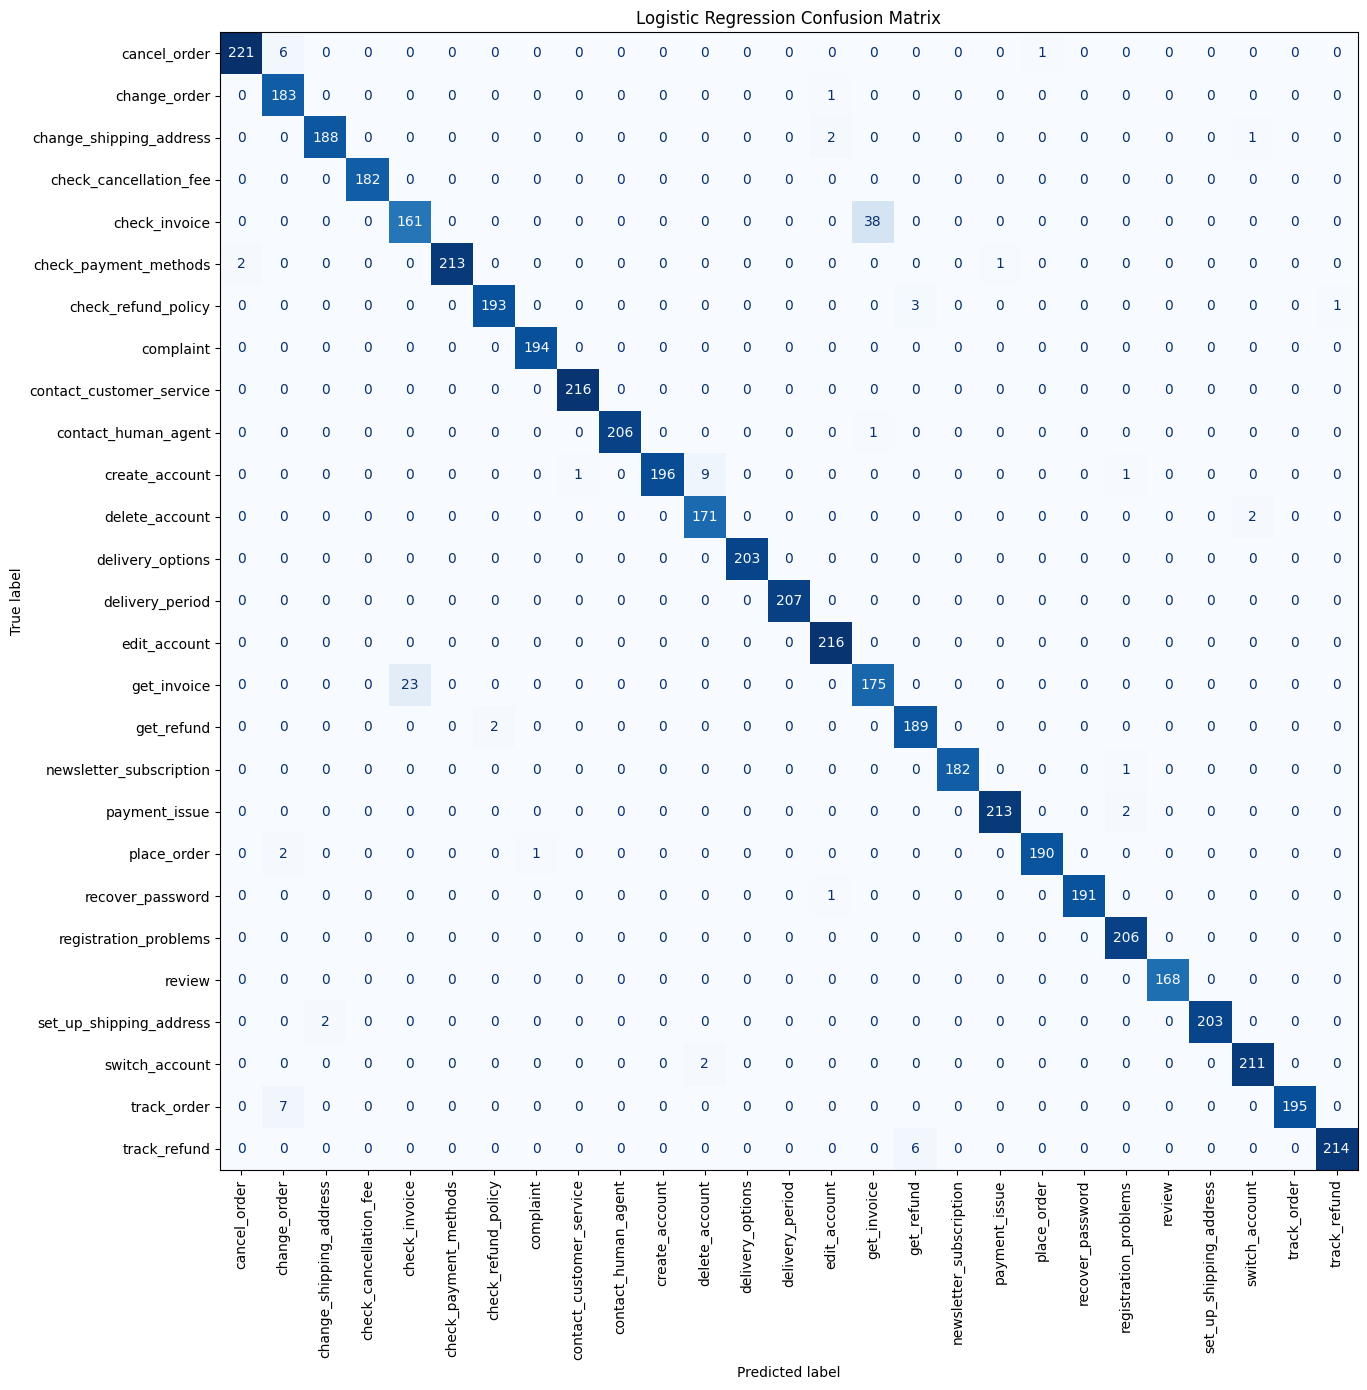

In [23]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(16, 14))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

### 12.3 Identify the most frequent classification errors

To identify the most frequent errors, the correct predictions on the main diagonal are set to zero. The remaining values represent cases where the model predicted one intent instead of another.

These incorrect prediction counts are then sorted so that the most frequent confusion pairs can be examined first.


In [24]:
errors = cm_df.copy()

# Set correct predictions (the diagonal) to zero
for label in errors.index:
    errors.loc[label, label] = 0

# Sort incorrect predictions from most frequent to least frequent
top_confusions = (
    errors.stack()
    .sort_values(ascending=False)
)

top_confusions = top_confusions[
    top_confusions > 0
].head(10)

print("TOP 10 MOST FREQUENT INTENT CONFUSIONS")
display(top_confusions)

TOP 10 MOST FREQUENT INTENT CONFUSIONS


,,0
check_invoice,get_invoice,38
get_invoice,check_invoice,23
create_account,delete_account,9
track_order,change_order,7
cancel_order,change_order,6
track_refund,get_refund,6
check_refund_policy,get_refund,3
change_shipping_address,edit_account,2
payment_issue,registration_problems,2
switch_account,delete_account,2


### 12.4 Inspect the customer messages behind the errors

This section displays customer instructions that Logistic Regression classified incorrectly.

For each selected error, the output shows the original instruction, its actual intent, and the intent predicted by the model. Reviewing these examples can help explain why certain intent classes are difficult to distinguish.


In [25]:
error_analysis = pd.DataFrame({
    "instruction": X_test,
    "actual_intent": y_test,
    "predicted_intent": y_pred_lr
})

# Keep only incorrectly classified messages
incorrect_predictions = error_analysis[
    error_analysis["actual_intent"] != error_analysis["predicted_intent"]
].copy()

# Display examples for each of the top confusion pairs
for (actual_label, predicted_label), error_count in top_confusions.items():
    examples = incorrect_predictions[
        (incorrect_predictions["actual_intent"] == actual_label) &
        (incorrect_predictions["predicted_intent"] == predicted_label)
    ]

    print(
        f"\nActual: {actual_label} | "
        f"Predicted: {predicted_label} | "
        f"Number of errors: {error_count}"
    )

    display(examples.head(10))


Actual: check_invoice | Predicted: get_invoice | Number of errors: 38


,instruction,actual_intent,predicted_intent
3959,find the bill from {{Person Name}},check_invoice,get_invoice
3987,find bil #12588,check_invoice,get_invoice
4006,see my blls from {{Person Name}},check_invoice,get_invoice
4010,need help lpocating the bloody invoice from {{...,check_invoice,get_invoice
4056,see invoicefrom {{Person Name}},check_invoice,get_invoice
4058,seebill from {{Person Name}},check_invoice,get_invoice
4074,i have got to see my invoice #12588 how can i ...,check_invoice,get_invoice
4102,"I want to find my bill from {{Person Name}}, I...",check_invoice,get_invoice
4147,I don't know what to do to see my invoice #00108,check_invoice,get_invoice
4177,I want assistance to see my invoice from {{Per...,check_invoice,get_invoice



Actual: get_invoice | Predicted: check_invoice | Number of errors: 23


,instruction,actual_intent,predicted_intent
14904,get invoice #37777,get_invoice,check_invoice
14940,i need assistance to get my bill #37777,get_invoice,check_invoice
14948,how can I get the invoices from {{Person Name}}?,get_invoice,check_invoice
14964,need to get the invoices from {{Person Name}},get_invoice,check_invoice
15019,can you help me get the bills from {{Person Na...,get_invoice,check_invoice
15047,i need assistance to get my invoices from {{P...,get_invoice,check_invoice
15059,want assistance to get the bills from {{Person...,get_invoice,check_invoice
15150,I call to get the bills from {{Person Name}},get_invoice,check_invoice
15164,could i get the damn invoice from {{Person Name}},get_invoice,check_invoice
15187,i want assistance to downlolad my bill #85632,get_invoice,check_invoice



Actual: create_account | Predicted: delete_account | Number of errors: 9


,instruction,actual_intent,predicted_intent
9926,I want assistance creatinga standard account,create_account,delete_account
10174,want help oopening a {{Account Type}} account,create_account,delete_account
10183,I want a {{Account Category}} account,create_account,delete_account
10289,another {{Account Type}} account,create_account,delete_account
10296,another {{Account Type}} account,create_account,delete_account
10300,I want a {{Account Type}} account,create_account,delete_account
10383,I want a pro account,create_account,delete_account
10589,another {{Account Type}} account,create_account,delete_account
10592,another pro account,create_account,delete_account


... (10 outputs left out)


Actual: payment_issue | Predicted: registration_problems | Number of errors: 2


,instruction,actual_intent,predicted_intent
18014,need to report an issue with paymentr,payment_issue,registration_problems
18817,I am trying to inform of an error with paymenys,payment_issue,registration_problems



Actual: switch_account | Predicted: delete_account | Number of errors: 2


,instruction,actual_intent,predicted_intent
24097,I don't know what I have to do to wsitch to th...,switch_account,delete_account
24589,what do i need to do to swigch to the standard...,switch_account,delete_account


## 13. Summary

This notebook has:

1. loaded and inspected the Bitext Customer Support dataset;
2. examined missing values, duplicated records, repeated instructions, and the distribution of categories and intents;
3. prepared the input messages and target labels;
4. divided the data into training and testing sets while keeping identical instruction texts together;
5. applied TF-IDF feature extraction;
6. trained and evaluated four traditional machine-learning models; and
7. examined Logistic Regression errors using a classification report and confusion matrix.

The model comparison and error analysis provide the results needed to answer the research question about which of the four traditional machine-learning models performs best on this dataset and experimental setup.
